# AML Baseline 1 — Independent EfficientNet-B0 | Google Colab | Patience 15

**Complete reproducible workflow.** Preserve original ImageNet-1K weights, two independent unfrozen CNNs, original augmentation, 6,905/695/400 development split, 8,000 full-data continuation, and **55 × 175 = 9,625** composition candidates.

**Changes in this revision:** Stage 1 patience **15** for C1/C2/C3 and D1/D2/D3; separate named experiment results; organized development and official-evaluation outputs; all six seen/unseen/H metrics; full and compact seen/unseen confusion matrices; image-based misclassification examples. **Stage 2 has no early stopping**.

**Run deliberately:** C1/C2/C3 and D1/D2/D3 are each independent ImageNet-pretrained runs; select which to run using `RUN_CROP` and `RUN_DISEASE`. Do not use official test to tune or select models. The official evaluation runs only after final checkpoints have been locked.

**Old checkpoints:** Changing patience from 5 to 15 does *not* retroactively change completed runs. Existing `best.pt` files remain valid old experiments, but to compare patience-15 runs fairly you must train a fresh run under a **new experiment name**, not overwrite earlier results.


## Cell 1 — Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cell 2 — Imports, Drive paths and shared settings

**Edit only `DRIVE_PROJECT`** if your My Drive shortcut has a different location. Each CNN hyperparameters appear immediately before its own training section.

In [ ]:
from pathlib import Path
import os, sys, shutil, subprocess, json, random, time, gc, copy, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import EfficientNet_B0_Weights
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

DRIVE_PROJECT = Path('/content/drive/MyDrive/DPD-Small')
LOCAL_PROJECT = Path('/content/DPD-Small')
RESULTS = Path('/content/drive/MyDrive/AML_B1_Clean_Results')
SEED = 42
NUM_WORKERS = 2
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'

assert DRIVE_PROJECT.exists(), f'Cannot find Drive project: {DRIVE_PROJECT}'
assert DEVICE.type == 'cuda', 'Enable a GPU: Runtime > Change runtime type > GPU'
RESULTS.mkdir(parents=True, exist_ok=True)
for folder in [
    'experiments/crop', 'experiments/disease',
    'development/combined_validation', 'development/experiment_comparisons',
    'fine_tuning', 'final',
    'official_evaluation/metrics', 'official_evaluation/predictions',
    'official_evaluation/confusion_matrices/seen',
    'official_evaluation/confusion_matrices/unseen',
    'official_evaluation/misclassification/seen',
    'official_evaluation/misclassification/unseen',
]:
    (RESULTS / folder).mkdir(parents=True, exist_ok=True)

DEVELOPMENT_DIR = RESULTS / 'development'
OFFICIAL_DIR = RESULTS / 'official_evaluation'
METRICS_DIR = OFFICIAL_DIR / 'metrics'
PREDICTIONS_DIR = OFFICIAL_DIR / 'predictions'
CONFUSION_DIR = OFFICIAL_DIR / 'confusion_matrices'
MISCLASS_DIR = OFFICIAL_DIR / 'misclassification'


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)
print('Project:', DRIVE_PROJECT)
print('Results:', RESULTS)

GPU: Tesla T4
PyTorch: 2.14.1+cu130
Project: /content/drive/MyDrive/DPD-Small
Results: /content/drive/MyDrive/AML_B1_Clean_Results


## Cell 3 — Copy all images and CSVs to Colab local storage (resumable)

Uses `rsync` so an interrupted copy can resume. This is the slowest preparation cell when Drive contains thousands of individual files. **Do not run model training until Cell 5 finds all required files.**

In [ ]:
LOCAL_PROJECT.mkdir(parents=True, exist_ok=True)

def find_child(parent, name):
    hits = [p for p in parent.iterdir() if p.name.lower() == name.lower()]
    if len(hits) != 1:
        raise FileNotFoundError(f'Expected {name} in {parent}; found {hits}')
    return hits[0]

start_copy = time.time()
for dirname in ['images', 'splits_v2']:
    src = find_child(DRIVE_PROJECT, dirname)
    dst = LOCAL_PROJECT / dirname
    dst.mkdir(parents=True, exist_ok=True)
    print(f'Copy/resume: {src} -> {dst}', flush=True)
    subprocess.run([
        'rsync', '-rt', '--size-only', '--info=progress2',
        str(src) + '/', str(dst) + '/'
    ], check=True)

for filename in ['DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_test_unseen.csv']:
    src = find_child(DRIVE_PROJECT, filename)
    shutil.copy2(src, LOCAL_PROJECT / filename)
    print('Copied CSV:', filename)

print(f'Copy complete in {(time.time()-start_copy)/60:.1f} min')

Copy/resume: /content/drive/MyDrive/DPD-Small/images -> /content/DPD-Small/images
Copy/resume: /content/drive/MyDrive/DPD-Small/splits_v2 -> /content/DPD-Small/splits_v2
Copied CSV: DPD_Small_train.csv
Copied CSV: DPD_Small_test_seen.csv
Copied CSV: DPD_Small_test_unseen.csv
Copy complete in 9.2 min


## Cell 4 — Load CSV files and verify the composition-aware split

Read the original headerless files correctly. Check **6,905 + 695 + 400 = 8,000**, no image overlap, and held-out crop–disease pairs are unseen to development training.

In [ ]:
COLUMNS = ['filename','crop_id','disease_id','composition_id',
           'crop_name','disease_name','composition_name']

def read_original_csv(path):
    # Original lecturer files have no header; also handles an unexpected header safely.
    with open(path, 'r', encoding='utf-8-sig') as f:
        first = f.readline().strip().split(',')
    has_header = first[0].strip().lower() == 'filename'
    df = pd.read_csv(path, header=0 if has_header else None,
                     names=COLUMNS, encoding='utf-8-sig')
    for col in ['crop_id','disease_id','composition_id']:
        df[col] = pd.to_numeric(df[col], errors='raise').astype(int)
    return df

train_df = pd.read_csv(LOCAL_PROJECT/'splits_v2/train_fit.csv')
val_seen_df = pd.read_csv(LOCAL_PROJECT/'splits_v2/val_seen.csv')
val_unseen_df = pd.read_csv(LOCAL_PROJECT/'splits_v2/val_unseen.csv')
full_train_df = read_original_csv(LOCAL_PROJECT/'DPD_Small_train.csv')
test_seen_df = read_original_csv(LOCAL_PROJECT/'DPD_Small_test_seen.csv')
test_unseen_df = read_original_csv(LOCAL_PROJECT/'DPD_Small_test_unseen.csv')

expected = {'train':6905,'val_seen':695,'val_unseen':400,'full_train':8000,
            'test_seen':2000,'test_unseen':1448}
datasets = {'train':train_df,'val_seen':val_seen_df,'val_unseen':val_unseen_df,
            'full_train':full_train_df,'test_seen':test_seen_df,'test_unseen':test_unseen_df}
for name, df in datasets.items():
    assert len(df) == expected[name], f'{name}: got {len(df)}, expected {expected[name]}'
    assert set(COLUMNS).issubset(df.columns), f'Missing metadata columns in {name}'
    assert df.filename.is_unique, f'Duplicate filenames in {name}'
    print(f'{name:12s}: {len(df):,} images')

file_sets = [set(df.filename) for df in (train_df,val_seen_df,val_unseen_df)]
assert not any(file_sets[i] & file_sets[j] for i in range(3) for j in range(i+1,3))
assert set().union(*file_sets) == set(full_train_df.filename)
assert not (set(full_train_df.filename) & (set(test_seen_df.filename)|set(test_unseen_df.filename)))
assert set(test_seen_df.filename).isdisjoint(set(test_unseen_df.filename))

def pairs(df):
    return set(map(tuple,df[['crop_id','disease_id']].astype(int).to_numpy()))

assert pairs(val_seen_df).issubset(pairs(train_df))
assert pairs(val_unseen_df).isdisjoint(pairs(train_df)|pairs(val_seen_df))
assert set(val_unseen_df.crop_id).issubset(set(train_df.crop_id))
assert set(val_unseen_df.disease_id).issubset(set(train_df.disease_id))
print('Split separation and unseen-composition coverage: PASS')
display(train_df.head(3))

train       : 6,905 images
val_seen    : 695 images
val_unseen  : 400 images
full_train  : 8,000 images
test_seen   : 2,000 images
test_unseen : 1,448 images
Split separation and unseen-composition coverage: PASS


,filename,crop_id,disease_id,composition_id,crop_name,disease_name,composition_name
0,BLSD_banana_sigatoka_615.jpeg,2,26,28,banana,sigatoka,banana_sigatoka
1,PD_paddy_bacterial_panicle_blight_1285.jpg,33,120,195,paddy,bacterial_panicle_blight,paddy_bacterial_panicle_blight
2,PWV2_peach_leaf_curl_6128.jpg,36,57,219,peach,curl,peach_curl


## Cell 5 — Index local image files and verify every CSV filename

If an interrupted copy left missing files, rerun Cell 3; do not skip this check.

In [ ]:
image_dir = LOCAL_PROJECT / 'images'
assert image_dir.is_dir(), f'No images folder: {image_dir}'
image_lookup = {}
duplicates = []
for p in tqdm(image_dir.rglob('*'), desc='Indexing local images'):
    if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}:
        if p.name in image_lookup:
            duplicates.append(p.name)
        image_lookup[p.name] = p
assert not duplicates, f'Duplicate basenames: {duplicates[:8]}'
needed = set().union(*(set(df.filename) for df in datasets.values()))
missing = needed - set(image_lookup)
print('Indexed:', len(image_lookup), '| Required unique:',len(needed),'| Missing:',len(missing))
assert not missing, f'Missing images (rerun Cell 3): {list(missing)[:10]}'
print('All required images are available locally.')

Indexing local images: 0it [00:00, ?it/s]

Indexed: 11469 | Required unique: 11448 | Missing: 0
All required images are available locally.


## Cell 6 — Training augmentation and deterministic validation/test preprocessing

Both networks use identical transforms. Training adds light augmentation; validation/testing use no random transformations.

In [ ]:
MEAN = (0.485,0.456,0.406)
STD = (0.229,0.224,0.225)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85,1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN,STD),
])
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN,STD),
])
def de_normalize(t):
    mu = torch.tensor(MEAN).view(3,1,1)
    sd = torch.tensor(STD).view(3,1,1)
    return (t.detach().cpu()*sd+mu).clamp(0,1).permute(1,2,0).numpy()
print('Transforms ready: random train augmentation; deterministic validation/test.')

Transforms ready: random train augmentation; deterministic validation/test.


## Cell 7 — Visual comparison: original vs two augmented views vs validation image

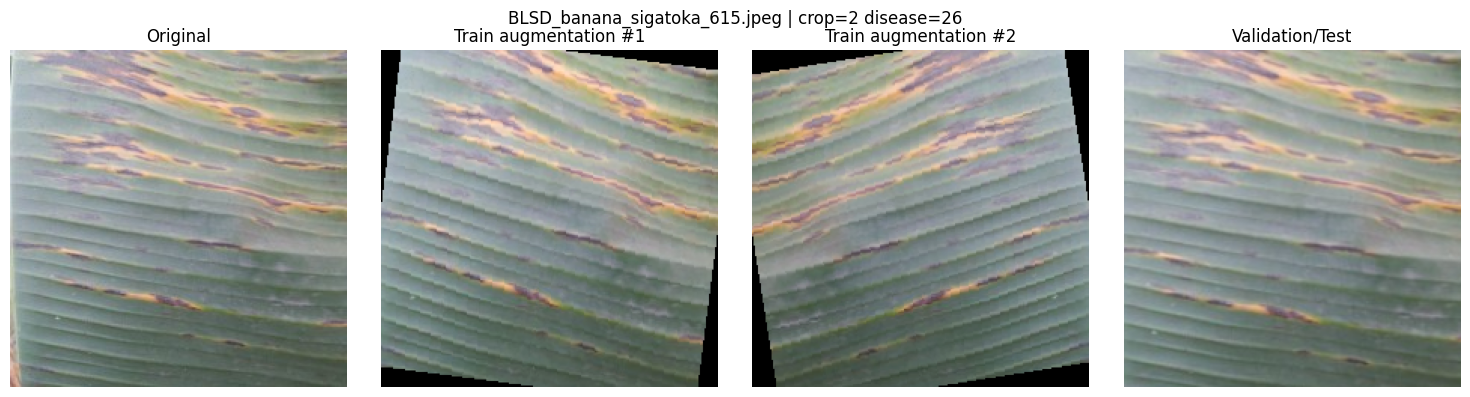

In [ ]:
r = train_df.iloc[0]
original = Image.open(image_lookup[r.filename]).convert('RGB')
fig, axes = plt.subplots(1,4,figsize=(15,4))
axes[0].imshow(original)
axes[1].imshow(de_normalize(train_transform(original)))
axes[2].imshow(de_normalize(train_transform(original)))
axes[3].imshow(de_normalize(eval_transform(original)))
for ax,ttl in zip(axes,['Original','Train augmentation #1','Train augmentation #2','Validation/Test']):
    ax.set_title(ttl)
    ax.axis('off')
plt.suptitle(f'{r.filename} | crop={r.crop_id} disease={r.disease_id}')
plt.tight_layout()
plt.show()

## Cell 8 — Shared PyTorch Dataset & DataLoaders

Every image returns both crop and disease labels. Crop training uses **only `crop_y`**, disease training uses **only `disease_y`**. Class-index mapping follows the original CSV IDs.

In [ ]:
crop_ids = sorted(map(int,full_train_df.crop_id.unique()))
disease_ids = sorted(map(int,full_train_df.disease_id.unique()))
assert len(crop_ids)==55, f'Expected 55 crops, got {len(crop_ids)}'
assert len(disease_ids)==175, f'Expected 175 diseases, got {len(disease_ids)}'
crop_to_idx = {c:i for i,c in enumerate(crop_ids)}
disease_to_idx = {d:i for i,d in enumerate(disease_ids)}
idx_to_crop = {i:c for c,i in crop_to_idx.items()}
idx_to_disease = {i:d for d,i in disease_to_idx.items()}
(RESULTS/'class_mapping.json').write_text(json.dumps({'crop_ids':crop_ids,'disease_ids':disease_ids},indent=2))

class PlantDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(image_lookup[str(row.filename)]) as im:
            x = self.transform(im.convert('RGB'))
        return (x, crop_to_idx[int(row.crop_id)], disease_to_idx[int(row.disease_id)])

def loader_for(df, train=False, batch_size=32):
    return DataLoader(
        PlantDataset(df, train_transform if train else eval_transform),
        batch_size=batch_size, shuffle=train, num_workers=NUM_WORKERS,
        pin_memory=True, persistent_workers=(NUM_WORKERS>0)
    )

seen_loader = loader_for(val_seen_df)
unseen_loader = loader_for(val_unseen_df)
print('Class mappings: crops=',len(crop_ids),'diseases=',len(disease_ids))
print('Validation batches:',len(seen_loader),'seen and',len(unseen_loader),'unseen')

Class mappings: crops= 55 diseases= 175
Validation batches: 22 seen and 13 unseen


## Cell 9 — Shared EfficientNet-B0 model, progress bars, evaluation & training utilities

Defines functions only: **no training starts here**. Training progress appears as a `tqdm` batch bar plus **one concise metric line per epoch**. Every experiment saves a unique best-H checkpoint and its seen/unseen validation score arrays.

In [ ]:
def make_model(task, pretrained=True, dropout=0.2):
    nclasses = {'crop':55,'disease':175}[task]
    weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    dim = model.classifier[1].in_features
    model.classifier = nn.Sequential(nn.Dropout(dropout),nn.Linear(dim,nclasses))
    return model.to(DEVICE)

def make_optimizer(model, cfg):
    return torch.optim.AdamW([
        {'params':model.features.parameters(), 'lr':cfg['backbone_lr']},
        {'params':model.classifier.parameters(), 'lr':cfg['head_lr']}
    ],weight_decay=cfg['weight_decay'])

def harmonic(a,b):
    return 0.0 if a+b==0 else 2*a*b/(a+b)

def experiment_path(task, name):
    return RESULTS/'experiments'/task/name

@torch.no_grad()
def evaluate_task(model, loader, task):
    model.eval()
    total_n = total_loss = correct1 = correct5 = 0
    criterion = nn.CrossEntropyLoss()
    for x, yc, yd in loader:
        x = x.to(DEVICE,non_blocking=True)
        y = (yc if task=='crop' else yd).to(DEVICE,non_blocking=True)
        with torch.autocast('cuda',enabled=AMP):
            logits = model(x)
            loss = criterion(logits,y)
        total_n += y.size(0)
        total_loss += loss.item()*y.size(0)
        top5 = logits.topk(5,dim=1).indices
        correct1 += (top5[:,0]==y).sum().item()
        correct5 += (top5==y[:,None]).any(1).sum().item()
    return {'loss':total_loss/total_n, 'top1':correct1/total_n,'top5':correct5/total_n}

def training_epoch(model, loader, task, optimizer, scaler, label):
    model.train()
    criterion = nn.CrossEntropyLoss()
    total_n=correct=0
    total_loss=0.0
    bar=tqdm(loader,desc=label,leave=False)
    for x,yc,yd in bar:
        x=x.to(DEVICE,non_blocking=True)
        y=(yc if task=='crop' else yd).to(DEVICE,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda',enabled=AMP):
            logits=model(x)
            loss=criterion(logits,y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        n=y.size(0)
        total_n+=n
        total_loss+=float(loss.detach())*n
        correct+=(logits.argmax(1)==y).sum().item()
        bar.set_postfix(loss=f'{total_loss/total_n:.3f}',acc=f'{correct/total_n:.1%}')
    return {'loss':total_loss/total_n,'top1':correct/total_n}

@torch.no_grad()
def predict_log_probs(model, loader):
    model.eval()
    outputs=[]
    for x,_,_ in loader:
        x=x.to(DEVICE,non_blocking=True)
        with torch.autocast('cuda',enabled=AMP):
            logits=model(x)
        outputs.append(F.log_softmax(logits.float(),dim=1).cpu().numpy())
    return np.concatenate(outputs,axis=0)

def save_ckpt(path, model, task, cfg, epoch, metric=None):
    path.parent.mkdir(parents=True,exist_ok=True)
    torch.save({
        'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
        'task':task, 'epoch':int(epoch), 'config':copy.deepcopy(cfg),
        'crop_ids':crop_ids,'disease_ids':disease_ids,'seed':SEED,
        'selection_metric':metric
    },path)

def load_model(path, expected_task):
    ck=torch.load(path,map_location='cpu',weights_only=False)
    assert ck['task']==expected_task
    assert ck['crop_ids']==crop_ids and ck['disease_ids']==disease_ids
    model=make_model(expected_task,pretrained=False,
                     dropout=ck.get('config',{}).get('dropout',0.2))
    model.load_state_dict(ck['state_dict'])
    return model,ck

def run_experiment(task,name,cfg):
    """Each model independently chooses best epoch by its own seen/unseen class H."""
    set_seed(SEED)
    out=experiment_path(task,name)
    if (out/'best.pt').exists():
        raise FileExistsError(f'Experiment {out} already exists. Change run name to avoid overwriting.')
    out.mkdir(parents=True,exist_ok=True)
    (out/'config.json').write_text(json.dumps(cfg,indent=2))
    model=make_model(task,pretrained=True,dropout=cfg['dropout'])
    optimizer=make_optimizer(model,cfg)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=cfg['epochs'])
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    train_loader=loader_for(train_df,train=True,batch_size=cfg['batch_size'])
    best_h=-1.0; best_epoch=None; patience_count=0; history=[]
    try:
        for epoch in range(1,cfg['epochs']+1):
            t=time.time()
            tr=training_epoch(model,train_loader,task,optimizer,scaler,f'{task.upper()} {name} {epoch}/{cfg["epochs"]}')
            sv=evaluate_task(model,seen_loader,task)
            uv=evaluate_task(model,unseen_loader,task)
            h=harmonic(sv['top1'],uv['top1'])
            improved=h>best_h+1e-9
            if improved:
                best_h=h;best_epoch=epoch;patience_count=0
                save_ckpt(out/'best.pt',model,task,cfg,epoch,metric=h)
                # Validation predictions are stored for pairing, never from test images.
                np.savez_compressed(out/'best_validation.npz',
                    seen=predict_log_probs(model,seen_loader),
                    unseen=predict_log_probs(model,unseen_loader))
            else:
                patience_count+=1
            history.append({
                'epoch':epoch,'train_loss':tr['loss'],'train_acc':tr['top1'],
                'seen_loss':sv['loss'],'seen_acc':sv['top1'],'seen_top5':sv['top5'],
                'unseen_loss':uv['loss'],'unseen_acc':uv['top1'],'unseen_top5':uv['top5'],
                'harmonic_mean':h,'best_h':best_h,'seconds':time.time()-t
            })
            pd.DataFrame(history).to_csv(out/'history.csv',index=False)
            scheduler.step()
            print(f'{task.upper():7s} {name} | Epoch {epoch:02d}/{cfg["epochs"]} | '
                  f'Train Loss {tr["loss"]:.4f} | Train Acc {tr["top1"]:.2%} | '
                  f'Seen Val {sv["top1"]:.2%} | Unseen Val {uv["top1"]:.2%} | '
                  f'H {h:.2%} | Best H {best_h:.2%} | Patience {patience_count}/{cfg["patience"]}',flush=True)
            if cfg['early_stopping'] and patience_count>=cfg['patience']:
                print(f'EARLY STOPPING: {task} | best epoch={best_epoch} | best H={best_h:.2%}')
                break
    finally:
        del model,optimizer,scheduler,scaler,train_loader
        gc.collect()
        if DEVICE.type=='cuda': torch.cuda.empty_cache()
    print(f'FINISHED {task}/{name}: best epoch={best_epoch} | H={best_h:.2%}')
    return pd.DataFrame(history)

def plot_experiment(task,name):
    df=pd.read_csv(experiment_path(task,name)/'history.csv')
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for col in ['train_loss','seen_loss','unseen_loss']:
        axes[0].plot(df.epoch,df[col],label=col)
    for col in ['train_acc','seen_acc','unseen_acc']:
        axes[1].plot(df.epoch,df[col]*100,label=col)
    axes[2].plot(df.epoch,df.harmonic_mean*100,label='Current H')
    axes[2].plot(df.epoch,df.best_h*100,label='Best H',linestyle='--')
    for ax,title in zip(axes,['Cross-entropy loss','Accuracy (%)','Individual harmonic mean (%)']):
        ax.set_title(title);ax.set_xlabel('Epoch');ax.grid(alpha=.2);ax.legend()
    plt.suptitle(f'{task.upper()} — {name}');plt.tight_layout()
    plt.savefig(experiment_path(task,name)/'curves.png',dpi=180)
    plt.show()

print('Reusable training functions ready. No CNN has been trained by this cell.')

Reusable training functions ready. No CNN has been trained by this cell.


STAGE 1 — C1 REFERENCE CROP CNN
Experiment: C1_reference_P15
Backbone LR: 1e-05
Head LR: 0.001
Max Epochs: 30
Patience: 15
RESULT TYPE: DEVELOPMENT VALIDATION ONLY
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s]


CROP C1_reference_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C1_reference_P15 | Epoch 01/30 | Train Loss 1.4634 | Train Acc 67.66% | Seen Val 74.53% | Unseen Val 54.50% | H 62.96% | Best H 62.96% | Patience 0/15


CROP C1_reference_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C1_reference_P15 | Epoch 02/30 | Train Loss 0.6356 | Train Acc 84.52% | Seen Val 79.71% | Unseen Val 57.00% | H 66.47% | Best H 66.47% | Patience 0/15


... (52 outputs left out)

CROP C1_reference_P15 29/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C1_reference_P15 | Epoch 29/30 | Train Loss 0.0456 | Train Acc 98.94% | Seen Val 87.63% | Unseen Val 65.50% | H 74.96% | Best H 76.95% | Patience 10/15


CROP C1_reference_P15 30/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C1_reference_P15 | Epoch 30/30 | Train Loss 0.0494 | Train Acc 98.83% | Seen Val 87.91% | Unseen Val 67.25% | H 76.21% | Best H 76.95% | Patience 11/15
FINISHED crop/C1_reference_P15: best epoch=19 | H=76.95%


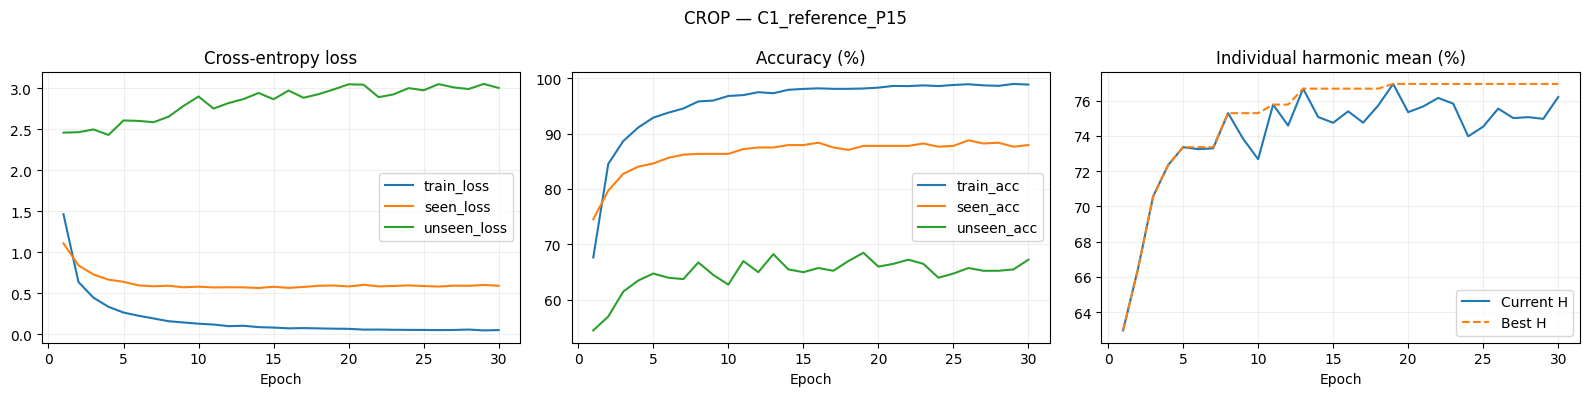


C1 DEVELOPMENT VALIDATION RESULTS SAVED TO:
/content/drive/MyDrive/AML_B1_Clean_Results/experiments/crop/C1_reference_P15
NO OFFICIAL TEST DATA WAS USED.


In [ ]:

# ============================================================
# CELL 9A — C1 REFERENCE CNN TRAINING (PATIENCE 15)
# ============================================================
# STAGE 1 — TRAINING + DEVELOPMENT VALIDATION ONLY
#
# Experiment: C1_reference_P15
# Model: ImageNet-pretrained EfficientNet-B0
# Task: Crop Classification (55 Classes)
#
# TRAINING DATA:
#   train_fit.csv — 6,905 images
#
# VALIDATION DATA:
#   val_seen.csv — 695 images
#   val_unseen.csv — 400 images
#
# NO FINE-TUNING
# NO OFFICIAL TESTING
# ============================================================

C1_P15_CONFIG = dict(
    backbone_lr=1e-5,
    head_lr=1e-3,
    batch_size=32,
    epochs=30,
    patience=15,
    early_stopping=True,
    weight_decay=1e-4,
    dropout=0.2
)

C1_P15_NAME = "C1_reference_P15"

print("=" * 80)
print("STAGE 1 — C1 REFERENCE CROP CNN")
print("Experiment:", C1_P15_NAME)
print("Backbone LR:", C1_P15_CONFIG["backbone_lr"])
print("Head LR:", C1_P15_CONFIG["head_lr"])
print("Max Epochs:", C1_P15_CONFIG["epochs"])
print("Patience:", C1_P15_CONFIG["patience"])
print("RESULT TYPE: DEVELOPMENT VALIDATION ONLY")
print("=" * 80)

c1_output = experiment_path("crop", C1_P15_NAME)

# Protect all existing training records.
if (c1_output / "best.pt").exists():

    print("Existing checkpoint found.")
    print("Skipping training to avoid overwriting results.")
    print("Note: checkpoint existence does not prove training completed.")

elif c1_output.exists() and any(c1_output.iterdir()):

    raise RuntimeError(
        f"Existing partial experiment files found: {c1_output}\n"
        "Review them before rerunning to prevent data loss."
    )

else:

    run_experiment(
        task="crop",
        name=C1_P15_NAME,
        cfg=C1_P15_CONFIG
    )

if (c1_output / "history.csv").exists():

    plot_experiment("crop", C1_P15_NAME)

print("\nC1 DEVELOPMENT VALIDATION RESULTS SAVED TO:")
print(c1_output)
print("NO OFFICIAL TEST DATA WAS USED.")


## Cell 10 — CROP CNN: set hyperparameters (easy to edit before training)

`RUN_CROP` is the list of experiments that actually run. Start with `C1_reference`; add a new experiment name to test different values. **Each experiment starts from fresh ImageNet-pretrained weights.**

**Patience = 15**. Default run list launches **C2_P15 and C3_P15** (change to run C1 if needed). Each experiment is independent and has separate `best.pt`, `history.csv`, `config.json`, `best_validation.npz`, `curves.png`. Existing experiments are protected from overwrite.

In [ ]:
CROP_EXPERIMENTS = {
    'C1_reference': dict(backbone_lr=1e-5, head_lr=1e-3, batch_size=32,
                         epochs=30, patience=15, early_stopping=True,
                         weight_decay=1e-4, dropout=0.2),
    'C2_lower_lr': dict(backbone_lr=5e-6, head_lr=5e-4, batch_size=32,
                        epochs=30, patience=15, early_stopping=True,
                        weight_decay=1e-4, dropout=0.2),
    'C3_head_lr': dict(backbone_lr=1e-5, head_lr=5e-4, batch_size=32,
                       epochs=30, patience=15, early_stopping=True,
                       weight_decay=1e-4, dropout=0.2),
}
# Patience-15 names prevent collisions with older patience-5 runs.
CROP_EXPERIMENTS.update({
    'C1_reference_P15': dict(CROP_EXPERIMENTS['C1_reference']),
    'C2_lower_lr_P15': dict(CROP_EXPERIMENTS['C2_lower_lr']),
    'C3_head_lr_P15': dict(CROP_EXPERIMENTS['C3_head_lr']),
})
RUN_CROP = ['C2_lower_lr_P15', 'C3_head_lr_P15']  # E.g. ['C2_lower_lr'] for your next run
print('Crop experiments:',RUN_CROP)
for name in RUN_CROP: print(name, CROP_EXPERIMENTS[name])

Crop experiments: ['C2_lower_lr_P15', 'C3_head_lr_P15']
C2_lower_lr_P15 {'backbone_lr': 5e-06, 'head_lr': 0.0005, 'batch_size': 32, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.2}
C3_head_lr_P15 {'backbone_lr': 1e-05, 'head_lr': 0.0005, 'batch_size': 32, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.2}


## Cell 11 — CROP CNN: train → seen/unseen validation → crop H → best checkpoint

Shows a **batch progress bar** and **one summary line per epoch**. The best checkpoint is selected by the **crop** harmonic mean, *not* validation loss.


=== CROP: C2_lower_lr_P15 ===
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 232MB/s]


CROP C2_lower_lr_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C2_lower_lr_P15 | Epoch 01/30 | Train Loss 1.9067 | Train Acc 59.06% | Seen Val 69.06% | Unseen Val 48.75% | H 57.16% | Best H 57.16% | Patience 0/15


CROP C2_lower_lr_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C2_lower_lr_P15 | Epoch 02/30 | Train Loss 0.9345 | Train Acc 78.55% | Seen Val 73.81% | Unseen Val 52.25% | H 61.19% | Best H 61.19% | Patience 0/15


... (52 outputs left out)

CROP C2_lower_lr_P15 29/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C2_lower_lr_P15 | Epoch 29/30 | Train Loss 0.1125 | Train Acc 97.20% | Seen Val 86.04% | Unseen Val 65.75% | H 74.54% | Best H 75.07% | Patience 11/15


CROP C2_lower_lr_P15 30/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C2_lower_lr_P15 | Epoch 30/30 | Train Loss 0.1190 | Train Acc 97.05% | Seen Val 87.05% | Unseen Val 66.75% | H 75.56% | Best H 75.56% | Patience 0/15
FINISHED crop/C2_lower_lr_P15: best epoch=30 | H=75.56%


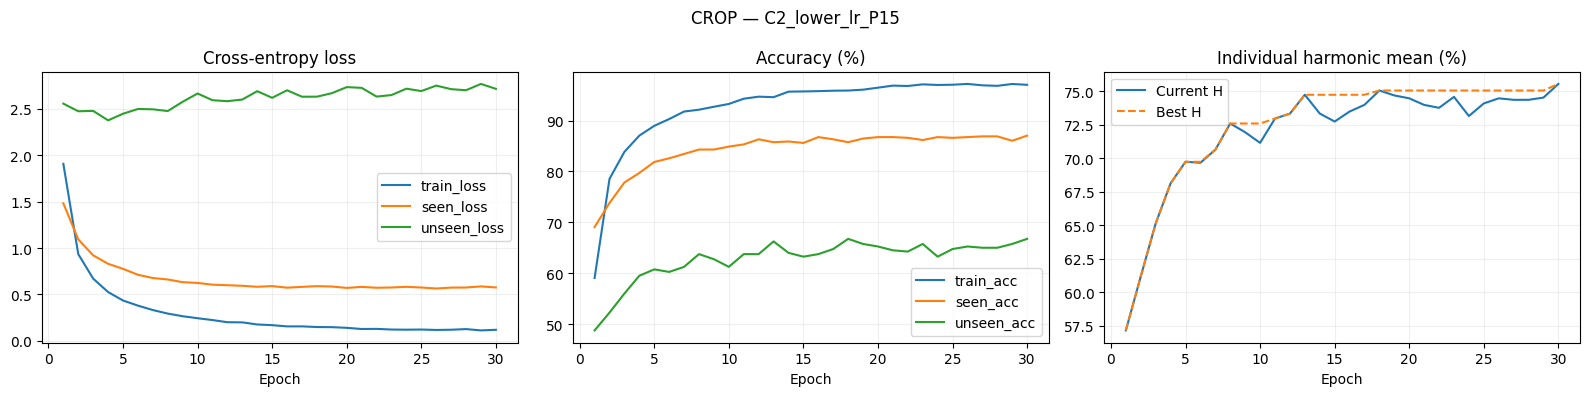


=== CROP: C3_head_lr_P15 ===


CROP C3_head_lr_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C3_head_lr_P15 | Epoch 01/30 | Train Loss 1.8377 | Train Acc 60.09% | Seen Val 71.22% | Unseen Val 50.25% | H 58.93% | Best H 58.93% | Patience 0/15


CROP C3_head_lr_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C3_head_lr_P15 | Epoch 02/30 | Train Loss 0.8461 | Train Acc 80.35% | Seen Val 75.97% | Unseen Val 53.75% | H 62.96% | Best H 62.96% | Patience 0/15


CROP C3_head_lr_P15 3/30:   0%|          | 0/216 [00:00<?, ?it/s]

... (51 outputs left out)

CROP C3_head_lr_P15 29/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C3_head_lr_P15 | Epoch 29/30 | Train Loss 0.0716 | Train Acc 98.31% | Seen Val 88.06% | Unseen Val 68.00% | H 76.74% | Best H 76.74% | Patience 0/15


CROP C3_head_lr_P15 30/30:   0%|          | 0/216 [00:00<?, ?it/s]

CROP    C3_head_lr_P15 | Epoch 30/30 | Train Loss 0.0662 | Train Acc 98.41% | Seen Val 87.19% | Unseen Val 67.25% | H 75.93% | Best H 76.74% | Patience 1/15
FINISHED crop/C3_head_lr_P15: best epoch=29 | H=76.74%


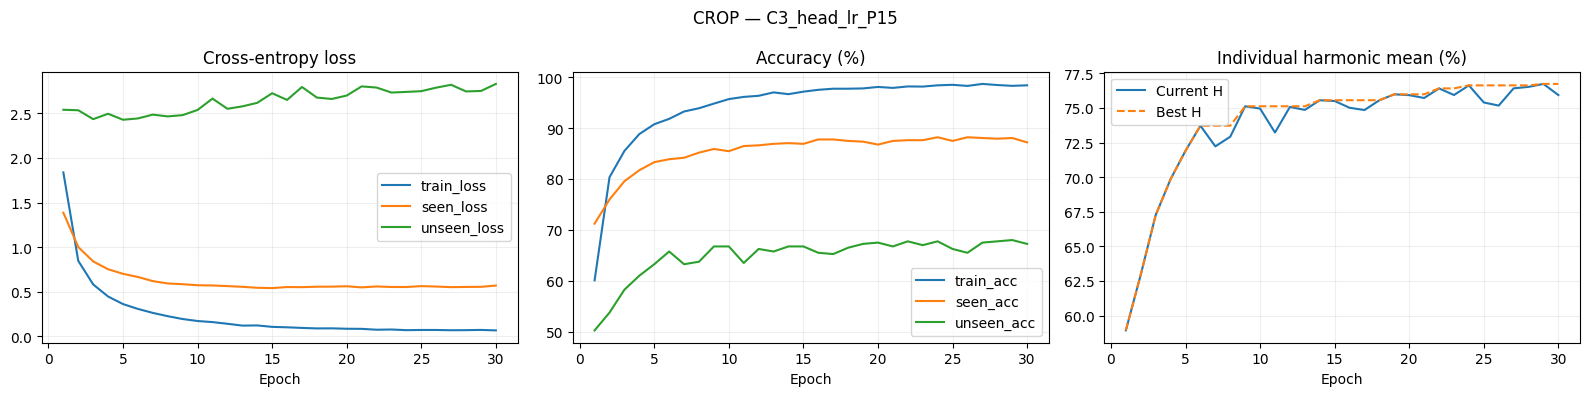

In [ ]:
for name in RUN_CROP:
    print(f'\n=== CROP: {name} ===',flush=True)
    if (experiment_path('crop',name)/'best.pt').exists():
        print(f'SKIP existing crop run: {name}; use a new run name to change patience.')
    else:
        run_experiment('crop',name,CROP_EXPERIMENTS[name])
    if (experiment_path('crop',name)/'history.csv').exists():
        plot_experiment('crop',name)

## Cell 12 — CROP CNN: experiment summary

In [ ]:
def experiment_summary(task):
    root=RESULTS/'experiments'/task
    rows=[]
    for d in sorted(root.iterdir()) if root.exists() else []:
        if not (d/'best.pt').exists():continue
        ck=torch.load(d/'best.pt',map_location='cpu',weights_only=False)
        rows.append({'experiment':d.name,'best_epoch':ck['epoch'],
                     'best_individual_H':ck['selection_metric'],
                     'backbone_lr':ck['config']['backbone_lr'],
                     'head_lr':ck['config']['head_lr']})
    assert rows, f'No completed {task} experiments found.'
    result=pd.DataFrame(rows).sort_values('best_individual_H',ascending=False)
    display(result.style.format({'best_individual_H':'{:.2%}'}))
    return result
crop_summary=experiment_summary('crop')

,experiment,best_epoch,best_individual_H,backbone_lr,head_lr
0,C1_reference_P15,19,76.95%,0.000010,0.001000
3,C3_head_lr_P15,29,76.74%,0.000010,0.000500
1,C1_reference_P5,13,76.68%,0.000010,0.001000
2,C2_lower_lr_P15,30,75.56%,0.000005,0.000500


STAGE 1 — D1 REFERENCE DISEASE CNN
Experiment: D1_reference_P15
Backbone LR: 1e-05
Head LR: 0.001
Max Epochs: 30
Patience: 15
RESULT TYPE: DEVELOPMENT VALIDATION ONLY


DISEASE D1_reference_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D1_reference_P15 | Epoch 01/30 | Train Loss 2.6506 | Train Acc 43.27% | Seen Val 51.65% | Unseen Val 13.00% | H 20.77% | Best H 20.77% | Patience 0/15


DISEASE D1_reference_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D1_reference_P15 | Epoch 02/30 | Train Loss 1.4872 | Train Acc 62.66% | Seen Val 58.99% | Unseen Val 13.50% | H 21.97% | Best H 21.97% | Patience 0/15


DISEASE D1_reference_P15 3/30:   0%|          | 0/216 [00:00<?, ?it/s]

... (51 outputs left out)

DISEASE D1_reference_P15 29/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D1_reference_P15 | Epoch 29/30 | Train Loss 0.2223 | Train Acc 93.76% | Seen Val 71.22% | Unseen Val 18.25% | H 29.06% | Best H 30.67% | Patience 3/15


DISEASE D1_reference_P15 30/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D1_reference_P15 | Epoch 30/30 | Train Loss 0.2034 | Train Acc 94.28% | Seen Val 72.09% | Unseen Val 18.50% | H 29.44% | Best H 30.67% | Patience 4/15
FINISHED disease/D1_reference_P15: best epoch=26 | H=30.67%


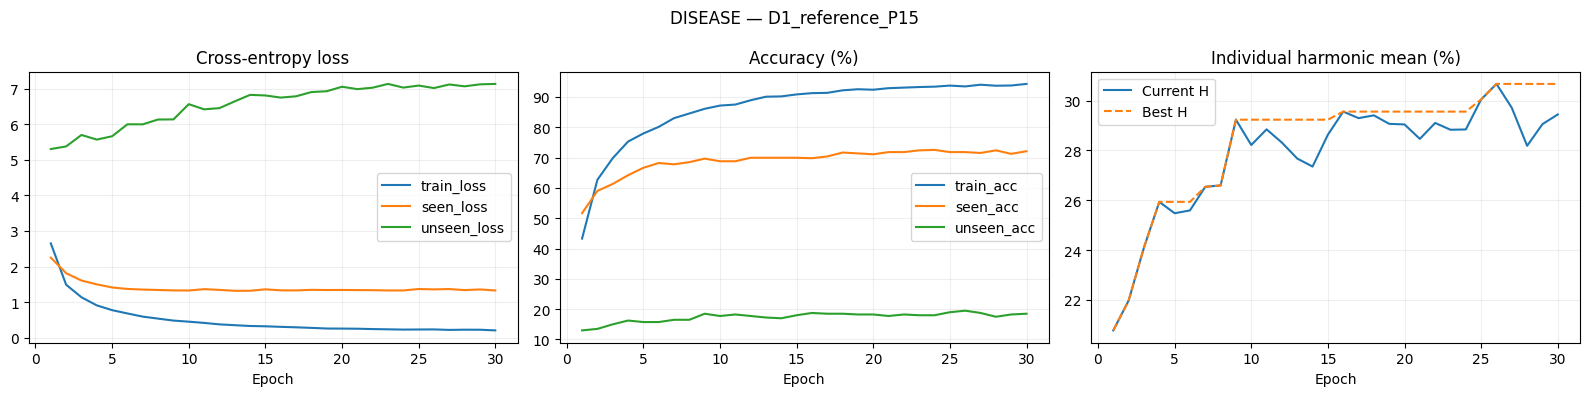


D1 DEVELOPMENT VALIDATION RESULTS SAVED TO:
/content/drive/MyDrive/AML_B1_Clean_Results/experiments/disease/D1_reference_P15
NO OFFICIAL TEST DATA WAS USED.


In [ ]:

# ============================================================
# CELL 12A — D1 REFERENCE CNN TRAINING (PATIENCE 15)
# ============================================================
# STAGE 1 — TRAINING + DEVELOPMENT VALIDATION ONLY
#
# Experiment: D1_reference_P15
# Model: ImageNet-pretrained EfficientNet-B0
# Task: Disease Classification (175 Classes)
#
# TRAINING DATA:
#   train_fit.csv — 6,905 images
#
# VALIDATION DATA:
#   val_seen.csv — 695 images
#   val_unseen.csv — 400 images
#
# NO FINE-TUNING
# NO OFFICIAL TESTING
# ============================================================

D1_P15_CONFIG = dict(
    backbone_lr=1e-5,
    head_lr=1e-3,
    batch_size=32,
    epochs=30,
    patience=15,
    early_stopping=True,
    weight_decay=1e-4,
    dropout=0.2
)

D1_P15_NAME = "D1_reference_P15"

print("=" * 80)
print("STAGE 1 — D1 REFERENCE DISEASE CNN")
print("Experiment:", D1_P15_NAME)
print("Backbone LR:", D1_P15_CONFIG["backbone_lr"])
print("Head LR:", D1_P15_CONFIG["head_lr"])
print("Max Epochs:", D1_P15_CONFIG["epochs"])
print("Patience:", D1_P15_CONFIG["patience"])
print("RESULT TYPE: DEVELOPMENT VALIDATION ONLY")
print("=" * 80)

d1_output = experiment_path("disease", D1_P15_NAME)

# Protect all existing training records.
if (d1_output / "best.pt").exists():

    print("Existing checkpoint found.")
    print("Skipping training to avoid overwriting results.")
    print("Note: checkpoint existence does not prove training completed.")

elif d1_output.exists() and any(d1_output.iterdir()):

    raise RuntimeError(
        f"Existing partial experiment files found: {d1_output}\n"
        "Review them before rerunning to prevent data loss."
    )

else:

    run_experiment(
        task="disease",
        name=D1_P15_NAME,
        cfg=D1_P15_CONFIG
    )

if (d1_output / "history.csv").exists():
    plot_experiment("disease", D1_P15_NAME)

print("\nD1 DEVELOPMENT VALIDATION RESULTS SAVED TO:")
print(d1_output)
print("NO OFFICIAL TEST DATA WAS USED.")


## Cell 13 — DISEASE CNN: set its own hyperparameters (then train next)

Independent model, optimizer, schedule, target labels, and harmonic-mean early stopping. You can change disease LRs without changing crop LRs.

**Patience = 15**. Default run list launches **D2_P15 and D3_P15**; edit it if you only want one experiment. Separate outputs per experiment.

In [ ]:
DISEASE_EXPERIMENTS = {
    'D1_reference': dict(backbone_lr=1e-5, head_lr=1e-3, batch_size=32,
                         epochs=30, patience=15, early_stopping=True,
                         weight_decay=1e-4, dropout=0.2),
    'D2_lower_lr': dict(backbone_lr=5e-6, head_lr=5e-4, batch_size=32,
                        epochs=30, patience=15, early_stopping=True,
                        weight_decay=1e-4, dropout=0.2),
    'D3_head_lr': dict(backbone_lr=1e-5, head_lr=5e-4, batch_size=32,
                       epochs=30, patience=15, early_stopping=True,
                       weight_decay=1e-4, dropout=0.2),
}
DISEASE_EXPERIMENTS.update({
    'D1_reference_P15': dict(DISEASE_EXPERIMENTS['D1_reference']),
    'D2_lower_lr_P15': dict(DISEASE_EXPERIMENTS['D2_lower_lr']),
    'D3_head_lr_P15': dict(DISEASE_EXPERIMENTS['D3_head_lr']),
})
RUN_DISEASE = ['D2_lower_lr_P15', 'D3_head_lr_P15']
print('Disease experiments:',RUN_DISEASE)
for name in RUN_DISEASE: print(name, DISEASE_EXPERIMENTS[name])

Disease experiments: ['D2_lower_lr_P15', 'D3_head_lr_P15']
D2_lower_lr_P15 {'backbone_lr': 5e-06, 'head_lr': 0.0005, 'batch_size': 32, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.2}
D3_head_lr_P15 {'backbone_lr': 1e-05, 'head_lr': 0.0005, 'batch_size': 32, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.2}


## Cell 14 — DISEASE CNN: train → seen/unseen validation → disease H → best checkpoint


=== DISEASE: D2_lower_lr_P15 ===


DISEASE D2_lower_lr_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D2_lower_lr_P15 | Epoch 01/30 | Train Loss 3.1166 | Train Acc 35.44% | Seen Val 44.60% | Unseen Val 12.25% | H 19.22% | Best H 19.22% | Patience 0/15


DISEASE D2_lower_lr_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D2_lower_lr_P15 | Epoch 02/30 | Train Loss 1.9341 | Train Acc 54.66% | Seen Val 52.81% | Unseen Val 13.25% | H 21.18% | Best H 21.18% | Patience 0/15


DISEASE D2_lower_lr_P15 3/30:   0%|          | 0/216 [00:00<?, ?it/s]

... (51 outputs left out)

DISEASE D2_lower_lr_P15 29/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D2_lower_lr_P15 | Epoch 29/30 | Train Loss 0.4239 | Train Acc 87.86% | Seen Val 68.63% | Unseen Val 17.75% | H 28.21% | Best H 28.90% | Patience 3/15


DISEASE D2_lower_lr_P15 30/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D2_lower_lr_P15 | Epoch 30/30 | Train Loss 0.4004 | Train Acc 88.79% | Seen Val 69.78% | Unseen Val 17.25% | H 27.66% | Best H 28.90% | Patience 4/15
FINISHED disease/D2_lower_lr_P15: best epoch=26 | H=28.90%


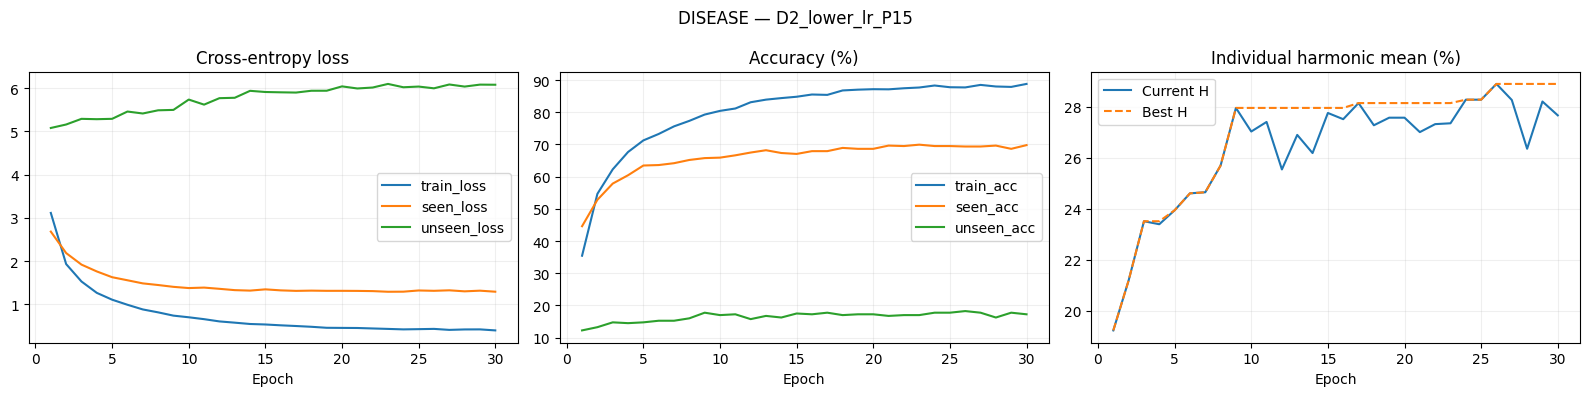


=== DISEASE: D3_head_lr_P15 ===


DISEASE D3_head_lr_P15 1/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D3_head_lr_P15 | Epoch 01/30 | Train Loss 3.0450 | Train Acc 36.25% | Seen Val 45.90% | Unseen Val 12.25% | H 19.34% | Best H 19.34% | Patience 0/15


DISEASE D3_head_lr_P15 2/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D3_head_lr_P15 | Epoch 02/30 | Train Loss 1.8334 | Train Acc 56.45% | Seen Val 54.10% | Unseen Val 13.50% | H 21.61% | Best H 21.61% | Patience 0/15


DISEASE D3_head_lr_P15 3/30:   0%|          | 0/216 [00:00<?, ?it/s]

... (51 outputs left out)

DISEASE D3_head_lr_P15 29/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D3_head_lr_P15 | Epoch 29/30 | Train Loss 0.3049 | Train Acc 91.56% | Seen Val 71.37% | Unseen Val 19.00% | H 30.01% | Best H 30.04% | Patience 2/15


DISEASE D3_head_lr_P15 30/30:   0%|          | 0/216 [00:00<?, ?it/s]

DISEASE D3_head_lr_P15 | Epoch 30/30 | Train Loss 0.2820 | Train Acc 92.54% | Seen Val 71.80% | Unseen Val 18.25% | H 29.10% | Best H 30.04% | Patience 3/15
FINISHED disease/D3_head_lr_P15: best epoch=27 | H=30.04%


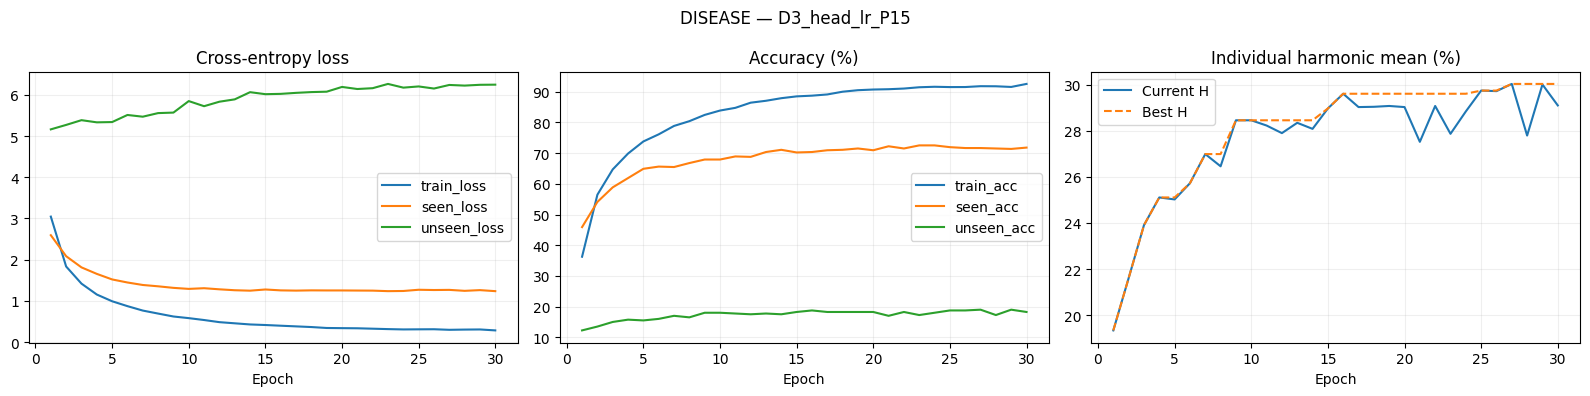

In [ ]:
for name in RUN_DISEASE:
    print(f'\n=== DISEASE: {name} ===',flush=True)
    if (experiment_path('disease',name)/'best.pt').exists():
        print(f'SKIP existing disease run: {name}; use a new run name to change patience.')
    else:
        run_experiment('disease',name,DISEASE_EXPERIMENTS[name])
    if (experiment_path('disease',name)/'history.csv').exists():
        plot_experiment('disease',name)

## Cell 15 — DISEASE CNN: experiment summary

In [ ]:
disease_summary=experiment_summary('disease')

,experiment,best_epoch,best_individual_H,backbone_lr,head_lr
0,D1_reference_P15,26,30.67%,0.000010,0.001000
3,D3_head_lr_P15,27,30.04%,0.000010,0.000500
1,D1_reference_P5,9,29.23%,0.000010,0.001000
2,D2_lower_lr_P15,26,28.90%,0.000005,0.000500


## Cell 16 — Combine best Crop and Disease checkpoints: rank **all 9,625** compositions

For image `x`, score all crop×disease pairs with `log P(c|x) + log P(d|x)`. This is the **full Cartesian product**; no filtering to 323+10 categories. Crop/Disease Top-1/5 and composition Top-1/5 are computed on seen/unseen validation. The composition harmonic mean is calculated separately from the crop and disease harmonics.

In [ ]:
CANDIDATE_PAIRS = [(c,d) for c in crop_ids for d in disease_ids]
assert len(CANDIDATE_PAIRS) == 55*175 == 9625
candidate_to_index={p:i for i,p in enumerate(CANDIDATE_PAIRS)}

def composition_metrics(crop_lp,disease_lp,df,save_predictions=False):
    assert crop_lp.shape==(len(df),55), crop_lp.shape
    assert disease_lp.shape==(len(df),175), disease_lp.shape
    ctrue=np.array([crop_to_idx[int(c)] for c in df.crop_id],dtype=np.int64)
    dtrue=np.array([disease_to_idx[int(d)] for d in df.disease_id],dtype=np.int64)
    cpred=np.argsort(-crop_lp,axis=1)[:,:5]
    dpred=np.argsort(-disease_lp,axis=1)[:,:5]
    # Full 55x175 joint ranks; flatten order matches CANDIDATE_PAIRS.
    joint=(crop_lp[:,:,None]+disease_lp[:,None,:]).reshape(-1,9625)
    # Top 5 from all 9,625 (argpartition plus exact sorting inside candidate top-5).
    ix=np.argpartition(-joint,kth=4,axis=1)[:,:5]
    top5=ix[np.arange(len(df))[:,None],np.argsort(-np.take_along_axis(joint,ix,axis=1),axis=1)]
    true_ix=ctrue*175+dtrue
    metrics={
        'crop_top1':float(np.mean(cpred[:,0]==ctrue)),
        'crop_top5':float(np.mean((cpred==ctrue[:,None]).any(axis=1))),
        'disease_top1':float(np.mean(dpred[:,0]==dtrue)),
        'disease_top5':float(np.mean((dpred==dtrue[:,None]).any(axis=1))),
        'composition_top1':float(np.mean(top5[:,0]==true_ix)),
        'composition_top5':float(np.mean((top5==true_ix[:,None]).any(axis=1))),
    }
    if not save_predictions:return metrics,None
    records=[]
    for i,rec in enumerate(df.itertuples(index=False)):
        ranked=[CANDIDATE_PAIRS[int(j)] for j in top5[i]]
        records.append({
            'filename':rec.filename,
            'true_crop_id':int(rec.crop_id),'true_disease_id':int(rec.disease_id),
            'true_composition_id':int(rec.composition_id),
            'pred_crop_id':crop_ids[int(cpred[i,0])],
            'pred_disease_id':disease_ids[int(dpred[i,0])],
            'pred_pair_crop_id':ranked[0][0],
            'pred_pair_disease_id':ranked[0][1],
            'top5_compositions':json.dumps(ranked)
        })
    return metrics,pd.DataFrame(records)

print('Candidate catalogue:',len(CANDIDATE_PAIRS),'pairs')

Candidate catalogue: 9625 pairs


## Cell 17 — Pick best INDIVIDUAL-H Crop CNN + best INDIVIDUAL-H Disease CNN, then evaluate combined validation

By your requested method, **Crop best epoch = highest crop H**, **Disease best epoch = highest disease H**. The chosen Crop and Disease epochs can differ. This cell also displays cross-experiment composition H for diagnosis, but does **not** silently replace your individual-H selection rule.

In [ ]:
crop_summary=experiment_summary('crop')
disease_summary=experiment_summary('disease')
SELECTED_CROP_RUN=str(crop_summary.iloc[0].experiment)
SELECTED_DISEASE_RUN=str(disease_summary.iloc[0].experiment)
print('Selected crop experiment:',SELECTED_CROP_RUN)
print('Selected disease experiment:',SELECTED_DISEASE_RUN)

def get_best_lp(task,run):
    p=experiment_path(task,run)/'best_validation.npz'
    with np.load(p) as z:
        return {'seen':z['seen'],'unseen':z['unseen']}

c_lp=get_best_lp('crop',SELECTED_CROP_RUN)
d_lp=get_best_lp('disease',SELECTED_DISEASE_RUN)
sv_metrics,sv_preds=composition_metrics(c_lp['seen'],d_lp['seen'],val_seen_df,True)
uv_metrics,uv_preds=composition_metrics(c_lp['unseen'],d_lp['unseen'],val_unseen_df,True)
composition_h=harmonic(sv_metrics['composition_top1'],uv_metrics['composition_top1'])
selected_report={'crop_run':SELECTED_CROP_RUN,'disease_run':SELECTED_DISEASE_RUN,
                 'selection_method':'highest individual crop H and disease H',
                 'candidate_pairs':9625,'seen_validation':sv_metrics,
                 'unseen_validation':uv_metrics,'composition_harmonic_mean':composition_h}
(DEVELOPMENT_DIR/'combined_validation/selected_development_pair.json').write_text(json.dumps(selected_report,indent=2))
sv_preds.to_csv(DEVELOPMENT_DIR/'combined_validation/seen_predictions.csv',index=False)
uv_preds.to_csv(DEVELOPMENT_DIR/'combined_validation/unseen_predictions.csv',index=False)
print('COMBINED VALIDATION | Seen composition:',f'{sv_metrics["composition_top1"]:.2%}',
      '| Unseen composition:',f'{uv_metrics["composition_top1"]:.2%}',
      '| Composition H:',f'{composition_h:.2%}')
display(pd.DataFrame({'seen_validation':sv_metrics,'unseen_validation':uv_metrics}).mul(100).round(2))

# Optional diagnostic: compare pairs of each experiment's individually selected checkpoint.
comparison=[]
for cname in crop_summary.experiment:
    clp=get_best_lp('crop',str(cname))
    for dname in disease_summary.experiment:
        dlp=get_best_lp('disease',str(dname))
        sm,_=composition_metrics(clp['seen'],dlp['seen'],val_seen_df)
        um,_=composition_metrics(clp['unseen'],dlp['unseen'],val_unseen_df)
        comparison.append({'crop_run':cname,'disease_run':dname,
                           'seen_composition_top1':sm['composition_top1'],
                           'unseen_composition_top1':um['composition_top1'],
                           'composition_H':harmonic(sm['composition_top1'],um['composition_top1'])})
comparison_df=pd.DataFrame(comparison).sort_values('composition_H',ascending=False)
comparison_df.to_csv(DEVELOPMENT_DIR/'experiment_comparisons/checkpoint_pair_comparison.csv',index=False)
display(comparison_df.style.format({
    'seen_composition_top1':'{:.2%}','unseen_composition_top1':'{:.2%}',
    'composition_H':'{:.2%}'}))
print('Primary selected pair remains the highest individual-H crop and disease experiments.')

,experiment,best_epoch,best_individual_H,backbone_lr,head_lr
0,C1_reference_P15,19,76.95%,0.000010,0.001000
3,C3_head_lr_P15,29,76.74%,0.000010,0.000500
1,C1_reference_P5,13,76.68%,0.000010,0.001000
2,C2_lower_lr_P15,30,75.56%,0.000005,0.000500


,experiment,best_epoch,best_individual_H,backbone_lr,head_lr
0,D1_reference_P15,26,30.67%,0.000010,0.001000
3,D3_head_lr_P15,27,30.04%,0.000010,0.000500
1,D1_reference_P5,9,29.23%,0.000010,0.001000
2,D2_lower_lr_P15,26,28.90%,0.000005,0.000500


Selected crop experiment: C1_reference_P15
Selected disease experiment: D1_reference_P15
COMBINED VALIDATION | Seen composition: 67.91% | Unseen composition: 4.75% | Composition H: 8.88%


,seen_validation,unseen_validation
crop_top1,87.77,68.50
crop_top5,95.25,76.00
disease_top1,71.80,19.50
disease_top5,88.49,32.75
composition_top1,67.91,4.75
composition_top5,84.46,11.75


,crop_run,disease_run,seen_composition_top1,unseen_composition_top1,composition_H
8,C1_reference_P5,D1_reference_P15,67.91%,5.75%,10.60%
10,C1_reference_P5,D1_reference_P5,66.33%,5.25%,9.73%
0,C1_reference_P15,D1_reference_P15,67.91%,4.75%,8.88%
9,C1_reference_P5,D3_head_lr_P15,67.63%,4.75%,8.88%
2,C1_reference_P15,D1_reference_P5,66.33%,4.50%,8.43%
11,C1_reference_P5,D2_lower_lr_P15,65.47%,4.50%,8.42%
4,C3_head_lr_P15,D1_reference_P15,68.78%,4.25%,8.01%
1,C1_reference_P15,D3_head_lr_P15,67.48%,4.00%,7.55%
6,C3_head_lr_P15,D1_reference_P5,67.19%,4.00%,7.55%
3,C1_reference_P15,D2_lower_lr_P15,65.61%,3.75%,7.09%


Primary selected pair remains the highest individual-H crop and disease experiments.


In [ ]:

# ============================================================
# CELL 17B — STAGE 1: INDIVIDUAL CNN DEVELOPMENT VALIDATION
# ============================================================
# DATASETS:
#   Seen Validation   : val_seen.csv   (695 images)
#   Unseen Validation : val_unseen.csv (400 images)
#
# PURPOSE:
#   Compare individual Crop and Disease CNN experiments.
#   Select promising hyperparameters and checkpoints.
#
# RESULTS ARE VALIDATION ONLY — NOT OFFICIAL TEST.
# No retraining or inference required.
# ============================================================

import pandas as pd
import torch

OUTPUT_DIR = (
    DEVELOPMENT_DIR / "experiment_comparisons"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def individual_validation_results(task):

    root = RESULTS / "experiments" / task
    rows = []

    assert root.exists(), f"Experiment folder not found: {root}"

    for folder in sorted(root.iterdir()):

        checkpoint_path = folder / "best.pt"
        history_path = folder / "history.csv"

        if not checkpoint_path.exists() or not history_path.exists():
            continue

        ck = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )

        history = pd.read_csv(history_path)
        cfg = ck["config"]

        best_epoch = int(ck["epoch"])

        best_rows = history.loc[
            history["epoch"] == best_epoch
        ]

        assert not best_rows.empty, (
            f"Best epoch {best_epoch} not found "
            f"in {history_path}"
        )

        best_row = best_rows.iloc[0]

        seen_acc = float(best_row["seen_acc"])
        unseen_acc = float(best_row["unseen_acc"])

        validation_h = (
            2 * seen_acc * unseen_acc / (seen_acc + unseen_acc)
            if seen_acc + unseen_acc > 0
            else 0.0
        )

        last_epoch = int(history["epoch"].max())

        early_stopping = cfg.get("early_stopping", False)
        patience = cfg.get("patience", None)
        max_epochs = int(cfg["epochs"])

        if last_epoch >= max_epochs:
            stop_reason = "Maximum Epochs"
        elif early_stopping:
            stop_reason = "Early Stopping / Incomplete"
        else:
            stop_reason = "Incomplete / Interrupted"

        rows.append({
            "Experiment": folder.name,
            "Best Epoch": best_epoch,
            "Last Epoch": last_epoch,
            "Max Epochs": max_epochs,
            "Seen Val Top-1 (%)": seen_acc * 100,
            "Unseen Val Top-1 (%)": unseen_acc * 100,
            "Validation H (%)": validation_h * 100,
            "Backbone LR": cfg["backbone_lr"],
            "Head LR": cfg["head_lr"],
            "Batch Size": cfg["batch_size"],
            "Dropout": cfg["dropout"],
            "Weight Decay": cfg["weight_decay"],
            "Patience": patience,
            "Early Stopping": early_stopping,
            "Stop Reason": stop_reason
        })

    assert rows, f"No saved {task} experiments found."

    result = (
        pd.DataFrame(rows)
        .sort_values(
            "Validation H (%)",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("\n" + "=" * 90)
    print(
        f"STAGE 1 — {task.upper()} CNN "
        "INDIVIDUAL DEVELOPMENT VALIDATION"
    )
    print("=" * 90)
    print("Seen Validation   : 695 images")
    print("Unseen Validation : 400 images")
    print("Selection Metric  : Individual Validation Harmonic Mean")
    print("RESULT TYPE       : VALIDATION ONLY — NOT OFFICIAL TEST")
    print("=" * 90)

    display(
        result.style.format({
            "Seen Val Top-1 (%)": "{:.2f}",
            "Unseen Val Top-1 (%)": "{:.2f}",
            "Validation H (%)": "{:.2f}",
            "Backbone LR": "{:.1e}",
            "Head LR": "{:.1e}",
            "Dropout": "{:.2f}",
            "Weight Decay": "{:.1e}"
        })
    )

    best = result.iloc[0]

    print(f"\nBEST {task.upper()} VALIDATION EXPERIMENT")
    print("Experiment :", best["Experiment"])
    print("Best Epoch :", best["Best Epoch"])
    print("Seen Val   :", f'{best["Seen Val Top-1 (%)"]:.2f}%')
    print("Unseen Val :", f'{best["Unseen Val Top-1 (%)"]:.2f}%')
    print("Best H     :", f'{best["Validation H (%)"]:.2f}%')

    return result


# ============================================================
# 1. CROP CNN — INDIVIDUAL VALIDATION
# ============================================================

crop_validation_results = individual_validation_results(
    "crop"
)

# ============================================================
# 2. DISEASE CNN — INDIVIDUAL VALIDATION
# ============================================================

disease_validation_results = individual_validation_results(
    "disease"
)

# ============================================================
# 3. SAVE VALIDATION RESULTS
# ============================================================

crop_path = (
    OUTPUT_DIR /
    "stage1_crop_individual_validation_results.csv"
)

disease_path = (
    OUTPUT_DIR /
    "stage1_disease_individual_validation_results.csv"
)

crop_validation_results.to_csv(crop_path, index=False)
disease_validation_results.to_csv(disease_path, index=False)

print("\n" + "=" * 90)
print("STAGE 1 INDIVIDUAL VALIDATION RESULTS SAVED")
print("Crop    :", crop_path)
print("Disease :", disease_path)
print("NO OFFICIAL TEST DATA WAS USED")
print("=" * 90)



STAGE 1 — CROP CNN INDIVIDUAL DEVELOPMENT VALIDATION
Seen Validation   : 695 images
Unseen Validation : 400 images
Selection Metric  : Individual Validation Harmonic Mean
RESULT TYPE       : VALIDATION ONLY — NOT OFFICIAL TEST


,Experiment,Best Epoch,Last Epoch,Max Epochs,Seen Val Top-1 (%),Unseen Val Top-1 (%),Validation H (%),Backbone LR,Head LR,Batch Size,Dropout,Weight Decay,Patience,Early Stopping,Stop Reason
0,C1_reference_P15,19,30,30,87.77,68.50,76.95,1.0e-05,1.0e-03,32,0.20,1.0e-04,15,True,Maximum Epochs
1,C3_head_lr_P15,29,30,30,88.06,68.00,76.74,1.0e-05,5.0e-04,32,0.20,1.0e-04,15,True,Maximum Epochs
2,C1_reference_P5,13,18,30,87.48,68.25,76.68,1.0e-05,1.0e-03,32,0.20,1.0e-04,5,True,Early Stopping / Incomplete
3,C2_lower_lr_P15,30,30,30,87.05,66.75,75.56,5.0e-06,5.0e-04,32,0.20,1.0e-04,15,True,Maximum Epochs



BEST CROP VALIDATION EXPERIMENT
Experiment : C1_reference_P15
Best Epoch : 19
Seen Val   : 87.77%
Unseen Val : 68.50%
Best H     : 76.95%

STAGE 1 — DISEASE CNN INDIVIDUAL DEVELOPMENT VALIDATION
Seen Validation   : 695 images
Unseen Validation : 400 images
Selection Metric  : Individual Validation Harmonic Mean
RESULT TYPE       : VALIDATION ONLY — NOT OFFICIAL TEST


,Experiment,Best Epoch,Last Epoch,Max Epochs,Seen Val Top-1 (%),Unseen Val Top-1 (%),Validation H (%),Backbone LR,Head LR,Batch Size,Dropout,Weight Decay,Patience,Early Stopping,Stop Reason
0,D1_reference_P15,26,30,30,71.80,19.50,30.67,1.0e-05,1.0e-03,32,0.20,1.0e-04,15,True,Maximum Epochs
1,D3_head_lr_P15,27,30,30,71.65,19.00,30.04,1.0e-05,5.0e-04,32,0.20,1.0e-04,15,True,Maximum Epochs
2,D1_reference_P5,9,14,30,69.64,18.50,29.23,1.0e-05,1.0e-03,32,0.20,1.0e-04,5,True,Early Stopping / Incomplete
3,D2_lower_lr_P15,26,30,30,69.35,18.25,28.90,5.0e-06,5.0e-04,32,0.20,1.0e-04,15,True,Maximum Epochs



BEST DISEASE VALIDATION EXPERIMENT
Experiment : D1_reference_P15
Best Epoch : 26
Seen Val   : 71.80%
Unseen Val : 19.50%
Best H     : 30.67%

STAGE 1 INDIVIDUAL VALIDATION RESULTS SAVED
Crop    : /content/drive/MyDrive/AML_B1_Clean_Results/development/experiment_comparisons/stage1_crop_individual_validation_results.csv
Disease : /content/drive/MyDrive/AML_B1_Clean_Results/development/experiment_comparisons/stage1_disease_individual_validation_results.csv
NO OFFICIAL TEST DATA WAS USED


In [ ]:

# ============================================================
# CELL 17C — STAGE 1: COMBINED COMPOSITION VALIDATION
# ============================================================
# DATASETS:
#   Seen Validation   : val_seen.csv   (695 images)
#   Unseen Validation : val_unseen.csv (400 images)
#
# MODEL PAIRS:
#   C1 / C2 / C3 x D1 / D2 / D3 = 9 pairs
#
# PREDICTION SPACE:
#   55 Crop Classes x 175 Disease Classes
#   = 9,625 Candidate Compositions
#
# PURPOSE:
#   Compare combined composition validation performance.
#
# VALIDATION ONLY — NOT OFFICIAL TEST.
# No retraining or inference required.
# ============================================================

import pandas as pd

OUTPUT_DIR = (
    DEVELOPMENT_DIR / "experiment_comparisons"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = (
    OUTPUT_DIR /
    "checkpoint_pair_comparison.csv"
)

assert comparison_path.exists(), (
    "Combined validation comparison not found. "
    "Run Cell 17 first."
)

# ============================================================
# 1. LOAD SAVED DEVELOPMENT VALIDATION RESULTS
# ============================================================

pair_results = pd.read_csv(comparison_path)

required_columns = {
    "crop_run",
    "disease_run",
    "seen_composition_top1",
    "unseen_composition_top1",
    "composition_H"
}

assert required_columns.issubset(pair_results.columns), (
    "Missing columns in saved comparison CSV."
)

pair_results = (
    pair_results
    .sort_values(
        "composition_H",
        ascending=False
    )
    .reset_index(drop=True)
)

# ============================================================
# 2. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 90)
print("STAGE 1 — COMBINED COMPOSITION DEVELOPMENT VALIDATION")
print("=" * 90)

print("Seen Validation   : 695 images")
print("Unseen Validation : 400 images")
print("Candidate Classes : 9,625 Crop-Disease Compositions")
print("Evaluation Metric : Composition Top-1 Harmonic Mean")
print("RESULT TYPE       : VALIDATION ONLY — NOT OFFICIAL TEST")

print("=" * 90)

display(
    pair_results.style.format({
        "seen_composition_top1": "{:.2%}",
        "unseen_composition_top1": "{:.2%}",
        "composition_H": "{:.2%}"
    })
)

# ============================================================
# 3. BEST COMBINED VALIDATION PAIR
# ============================================================

best_pair = pair_results.iloc[0]

print("\n" + "=" * 90)
print("BEST CROP × DISEASE PAIR — DEVELOPMENT VALIDATION")
print("=" * 90)

print("Crop CNN       :", best_pair["crop_run"])
print("Disease CNN    :", best_pair["disease_run"])

print(
    "Seen Val Top-1 :",
    f'{best_pair["seen_composition_top1"]:.2%}'
)

print(
    "Unseen Val Top-1:",
    f'{best_pair["unseen_composition_top1"]:.2%}'
)

print(
    "Composition H  :",
    f'{best_pair["composition_H"]:.2%}'
)

print("\nNOTE:")
print("This is the highest combined validation H.")
print("It may differ from the pair selected using individual H.")
print("The final selection rule must be fixed before official testing.")

# ============================================================
# 4. SAVE CLEARLY LABELLED VALIDATION CSV
# ============================================================

save_path = (
    OUTPUT_DIR /
    "stage1_combined_composition_validation_results.csv"
)

pair_results.to_csv(save_path, index=False)

print("\n" + "=" * 90)
print("COMBINED DEVELOPMENT VALIDATION RESULTS SAVED")
print("Saved:", save_path)
print("NO OFFICIAL TEST DATA WAS USED")
print("=" * 90)



STAGE 1 — COMBINED COMPOSITION DEVELOPMENT VALIDATION
Seen Validation   : 695 images
Unseen Validation : 400 images
Candidate Classes : 9,625 Crop-Disease Compositions
Evaluation Metric : Composition Top-1 Harmonic Mean
RESULT TYPE       : VALIDATION ONLY — NOT OFFICIAL TEST


,crop_run,disease_run,seen_composition_top1,unseen_composition_top1,composition_H
0,C1_reference_P5,D1_reference_P15,67.91%,5.75%,10.60%
1,C1_reference_P5,D1_reference_P5,66.33%,5.25%,9.73%
2,C1_reference_P15,D1_reference_P15,67.91%,4.75%,8.88%
3,C1_reference_P5,D3_head_lr_P15,67.63%,4.75%,8.88%
4,C1_reference_P15,D1_reference_P5,66.33%,4.50%,8.43%
5,C1_reference_P5,D2_lower_lr_P15,65.47%,4.50%,8.42%
6,C3_head_lr_P15,D1_reference_P15,68.78%,4.25%,8.01%
7,C1_reference_P15,D3_head_lr_P15,67.48%,4.00%,7.55%
8,C3_head_lr_P15,D1_reference_P5,67.19%,4.00%,7.55%
9,C1_reference_P15,D2_lower_lr_P15,65.61%,3.75%,7.09%



BEST CROP × DISEASE PAIR — DEVELOPMENT VALIDATION
Crop CNN       : C1_reference_P5
Disease CNN    : D1_reference_P15
Seen Val Top-1 : 67.91%
Unseen Val Top-1: 5.75%
Composition H  : 10.60%

NOTE:
This is the highest combined validation H.
It may differ from the pair selected using individual H.
The final selection rule must be fixed before official testing.

COMBINED DEVELOPMENT VALIDATION RESULTS SAVED
Saved: /content/drive/MyDrive/AML_B1_Clean_Results/development/experiment_comparisons/stage1_combined_composition_validation_results.csv
NO OFFICIAL TEST DATA WAS USED


## Cell 18 — Stage 2 shared fine-tuning helper (NO early stopping)

Each final model starts **from its selected development checkpoint**, not from ImageNet again. All **8,000 images** return to training. Every fine-tuning epoch saves a separate checkpoint; **training curves** can be inspected before manually selecting a final epoch. Keep learning rates low and the number of epochs conservative. Avoid using the official test set for any selection.

In [ ]:
assert len(full_train_df)==8000
assert set(full_train_df.filename)==set(train_df.filename)|set(val_seen_df.filename)|set(val_unseen_df.filename)

def finetune(task,source_run,cfg):
    source=experiment_path(task,source_run)/'best.pt'
    assert source.exists(),f'Selected development checkpoint missing: {source}'
    out=RESULTS/'fine_tuning'/task
    if (out/'history.csv').exists():
        raise FileExistsError(f'Fine-tuning output already exists: {out}. Change output folder or archive old results before rerunning.')
    out.mkdir(parents=True,exist_ok=True)
    (out/'config.json').write_text(json.dumps({'source_run':source_run,**cfg},indent=2))
    model,ck=load_model(source,task)
    print(f'{task.upper()} fine-tuning: continuing development epoch {ck["epoch"]}, 8,000 images')
    opt=make_optimizer(model,cfg)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=cfg['epochs'])
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    ld=loader_for(full_train_df,train=True,batch_size=cfg['batch_size'])
    rows=[]
    try:
        for epoch in range(1,cfg['epochs']+1):
            stats=training_epoch(model,ld,task,opt,scaler,f'FINE-TUNE {task.upper()} {epoch}/{cfg["epochs"]}')
            scheduler.step()
            rows.append({'epoch':epoch,'train_loss':stats['loss'],'train_acc':stats['top1']})
            save_ckpt(out/f'epoch_{epoch:02d}.pt',model,task,cfg,epoch)
            pd.DataFrame(rows).to_csv(out/'history.csv',index=False)
            print(f'FINE-TUNE {task.upper()} | Epoch {epoch:02d}/{cfg["epochs"]} | '
                  f'Train Loss {stats["loss"]:.4f} | Train Acc {stats["top1"]:.2%} | '
                  'No validation / No early stopping',flush=True)
    finally:
        del model,opt,scheduler,scaler,ld
        gc.collect()
        if DEVICE.type=='cuda': torch.cuda.empty_cache()
    plot_finetune(task)

def plot_finetune(task):
    out=RESULTS/'fine_tuning'/task
    df=pd.read_csv(out/'history.csv')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    axes[0].plot(df.epoch,df.train_loss,marker='o')
    axes[1].plot(df.epoch,df.train_acc*100,marker='o')
    axes[0].set_title(f'{task.upper()} fine-tune training loss')
    axes[1].set_title(f'{task.upper()} fine-tune training accuracy (%)')
    for ax in axes: ax.set_xlabel('Fine-tuning epoch');ax.grid(alpha=.25)
    plt.tight_layout()
    plt.savefig(out/'fine_tune_curves.png',dpi=180)
    plt.show()
    print('Maximum recorded training accuracy epoch:',int(df.loc[df.train_acc.idxmax(),'epoch']))
    print('This is a training-fit diagnostic, not proof of generalisation.')

print('Full-data fine-tuning functions ready. Not started.')

Full-data fine-tuning functions ready. Not started.


## Cell 19 — CROP final fine-tuning: set low LR immediately before running

Set `RUN_CROP_FINETUNE=True` after development results are reviewed. The example 5 epochs / low LRs are provisional. This runs **without early stopping** and saves training graphs and epoch checkpoints.

In [ ]:
CROP_FINETUNE_CFG={
    'backbone_lr':1e-6,
    'head_lr':1e-4,
    'batch_size':32,
    'epochs':5,
    'weight_decay':1e-4,
    'dropout':0.2,
}
RUN_CROP_FINETUNE=False  # change when ready
if RUN_CROP_FINETUNE:
    finetune('crop',SELECTED_CROP_RUN,CROP_FINETUNE_CFG)
else:
    print('Crop fine-tuning not started. Review development results first.')

Crop fine-tuning not started. Review development results first.


## Cell 20 — DISEASE final fine-tuning: separate low-LR config + training

Runs independently and saves separate checkpoints. Again, **no validation early stopping**.

In [ ]:
DISEASE_FINETUNE_CFG={
    'backbone_lr':1e-6,
    'head_lr':1e-4,
    'batch_size':32,
    'epochs':5,
    'weight_decay':1e-4,
    'dropout':0.2,
}
RUN_DISEASE_FINETUNE=False  # change when ready
if RUN_DISEASE_FINETUNE:
    finetune('disease',SELECTED_DISEASE_RUN,DISEASE_FINETUNE_CFG)
else:
    print('Disease fine-tuning not started. Review development results first.')

Disease fine-tuning not started. Review development results first.


## Cell 21 — Inspect both fine-tuning graphs and MANUALLY choose final checkpoints

**You decide which saved epoch to use** after reviewing the training curves and pre-decided fine-tuning duration. Default values are the **last epoch**. The selection is not made using official test accuracy. No need to interrupt a Colab cell manually; it automatically runs the configured number of epochs.

In [ ]:
RUN_SELECT_FINAL=False  # set True only after both fine-tuning runs are complete

# Set these after inspecting the loss/accuracy graphs.
# E.g. choose 3 rather than 5 to use the third fine-tuned checkpoint.
CROP_FINAL_EPOCH=5
DISEASE_FINAL_EPOCH=5

if RUN_SELECT_FINAL:
    for task,epoch in [('crop',CROP_FINAL_EPOCH),('disease',DISEASE_FINAL_EPOCH)]:
        plot_finetune(task)
        source=RESULTS/'fine_tuning'/task/f'epoch_{epoch:02d}.pt'
        assert source.exists(),f'Missing checkpoint: {source}'
        dest=RESULTS/'final'/f'{task}_b1_final.pt'
        dest.parent.mkdir(parents=True,exist_ok=True)
        shutil.copy2(source,dest)
        print(f'Final {task}: fine-tuning epoch {epoch} -> {dest}')
    (RESULTS/'final'/'final_selection.json').write_text(json.dumps({
        'crop_run':SELECTED_CROP_RUN,'disease_run':SELECTED_DISEASE_RUN,
        'crop_finetune_epoch':CROP_FINAL_EPOCH,
        'disease_finetune_epoch':DISEASE_FINAL_EPOCH,
        'selection_note':'Manual choice without official test feedback'
    },indent=2))
else:
    print('Final model selection is disabled. Review graphs and enable when ready.')

Final model selection is disabled. Review graphs and enable when ready.


## Cell 22 — Official seen & unseen evaluation: Crop / Disease / 9,625-composition Top-1 & Top-5

**Only run after you have frozen your fine-tuned checkpoints and evaluation rules.** Official tests must not influence tuning or epoch selection.

In [ ]:
RUN_OFFICIAL_TEST=False  # set True ONCE after final model selection

if RUN_OFFICIAL_TEST:
    assert (RESULTS/'final/crop_b1_final.pt').exists()
    assert (RESULTS/'final/disease_b1_final.pt').exists()
    assert len(test_seen_df)==2000 and len(test_unseen_df)==1448
    assert set(test_seen_df.crop_id).union(test_unseen_df.crop_id).issubset(crop_to_idx)
    assert set(test_seen_df.disease_id).union(test_unseen_df.disease_id).issubset(disease_to_idx)
    cm, _ = load_model(RESULTS/'final/crop_b1_final.pt','crop')
    dm, _ = load_model(RESULTS/'final/disease_b1_final.pt','disease')
    test_results={}
    official_predictions={}
    for label,df in [('seen',test_seen_df),('unseen',test_unseen_df)]:
        ld=loader_for(df,train=False,batch_size=32)
        cp=predict_log_probs(cm,ld)
        dp=predict_log_probs(dm,ld)
        stats,pred=composition_metrics(cp,dp,df,save_predictions=True)
        test_results[label]=stats
        official_predictions[label]=pred
        pred.to_csv(PREDICTIONS_DIR/f'{label}_predictions.csv',index=False)
    official_H=harmonic(test_results['seen']['composition_top1'],
                        test_results['unseen']['composition_top1'])
    official_summary={'candidate_compositions':9625,
                      'seen':test_results['seen'],'unseen':test_results['unseen'],
                      'composition_top1_harmonic_mean':official_H,
                      'composition_seen_unseen_gap':test_results['seen']['composition_top1']-test_results['unseen']['composition_top1']}
    (METRICS_DIR/'official_metrics.json').write_text(json.dumps(official_summary,indent=2))
    display(pd.DataFrame(test_results).mul(100).round(2))
    print('OFFICIAL COMPOSITION H:',f'{official_H:.2%}')

    # All six harmonic means, not only the primary composition Top-1.
    metric_keys = ['crop_top1','crop_top5','disease_top1','disease_top5','composition_top1','composition_top5']
    evaluation_rows = []
    for key in metric_keys:
        a = test_results['seen'][key]
        b = test_results['unseen'][key]
        evaluation_rows.append({'metric':key, 'seen_percent':100*a,
                                'unseen_percent':100*b, 'harmonic_mean_percent':100*harmonic(a,b)})
    evaluation_df = pd.DataFrame(evaluation_rows)
    evaluation_df.to_csv(METRICS_DIR/'seen_unseen_all_harmonic_means.csv',index=False)
    display(evaluation_df.round(2))
    print('Primary metric — COMPOSITION TOP-1 H:',f'{official_H:.2%}')
    del cm,dm
    gc.collect()
    torch.cuda.empty_cache()
else:
    print('Official testing disabled until final checkpoints are selected.')

Official testing disabled until final checkpoints are selected.


## Official evaluation analysis — readable confusion matrices + misclassified images

Run **after** official testing; or after restarting the kernel, load existing CSVs from `official_evaluation/predictions/`. The confusion-matrix plots **do not rerank or restrict** the prediction space: predictions have already been selected from all **9,625** candidates.

- **Full confusion matrix:** all true compositions in each split + `OTHER`, row-normalized and counts; CSV/PNG saved separately for Seen and Unseen.
- **Compact matrix:** Seen **Top 10** by ground-truth frequency; Unseen **all 10** true combinations; `OTHER` means prediction outside the displayed classes. Compact plots show only selected rows and therefore do not represent the full 2,000-image seen accuracy.
- **Misclassification:** each split gets an error CSV, most common error CSV, and a figure showing original pictures with ground truth vs predicted crop–disease names.


In [ ]:
# ===========================================================
# OFFICIAL CONFUSION MATRICES — FULL + COMPACT, SEEN + UNSEEN
# Data source: saved predictions from the official 9,625-way evaluation.
# No GPU or retraining needed. Outputs in CONFUSION_DIR / split /.
# ===========================================================
import textwrap
from matplotlib.colors import PowerNorm

TOP_N_SEEN = 10              # compact seen display only
COMPACT_FIGSIZE = (10, 7)   # small readable plot
SHOW_FULL_MATRIX = False    # full CSV is ALWAYS saved; plot only if desired
SHOW_COMPACT_MATRIX = True

def official_prediction_frame(split):
    if 'official_predictions' in globals() and split in official_predictions:
        return official_predictions[split].copy()
    path = PREDICTIONS_DIR / f'{split}_predictions.csv'
    assert path.exists(), f'Missing {path}; run official evaluation first.'
    return pd.read_csv(path)

crop_names = full_train_df[['crop_id','crop_name']].drop_duplicates('crop_id').set_index('crop_id').crop_name.to_dict()
disease_names = full_train_df[['disease_id','disease_name']].drop_duplicates('disease_id').set_index('disease_id').disease_name.to_dict()

def readable_pair(pair, width=27):
    c,d = map(int,pair)
    label = f'{crop_names.get(c,str(c))} / {disease_names.get(d,str(d))}'
    return textwrap.fill(label,width=width)

def pair_columns(df):
    df = df.copy()
    df['true_pair'] = list(zip(df.true_crop_id.astype(int), df.true_disease_id.astype(int)))
    df['pred_pair'] = list(zip(df.pred_pair_crop_id.astype(int), df.pred_pair_disease_id.astype(int)))
    return df

def create_matrix(df, selected_classes):
    lookup = {p:i for i,p in enumerate(selected_classes)}
    subset = df[df.true_pair.isin(selected_classes)]
    n = len(selected_classes)
    mat = np.zeros((n,n+1),dtype=np.int64)
    for row in subset.itertuples():
        mat[lookup[row.true_pair], lookup.get(row.pred_pair,n)] += 1
    assert mat.sum() == len(subset)
    norm = np.divide(mat, mat.sum(axis=1,keepdims=True),
                     out=np.zeros_like(mat,dtype=float),where=mat.sum(axis=1,keepdims=True)!=0)
    return mat,norm,len(subset)

def draw_cm(mat,norm,classes,split,mode,out_dir,compact=False):
    n=len(classes)
    labels=[readable_pair(pair) for pair in classes]
    pd.DataFrame(mat,index=labels,columns=labels+['OTHER']).to_csv(out_dir/f'{mode}_counts.csv')
    pd.DataFrame(norm,index=labels,columns=labels+['OTHER']).to_csv(out_dir/f'{mode}_normalized.csv')
    if not compact and not SHOW_FULL_MATRIX:
        print(f'{split.upper()} full matrix CSV files saved ({mat.shape}); plot disabled for readability.')
        return
    fig,ax=plt.subplots(figsize=COMPACT_FIGSIZE if compact else (15,12))
    im=ax.imshow(norm,aspect='auto',interpolation='nearest',cmap='Blues',
                 norm=PowerNorm(gamma=0.45,vmin=0,vmax=1))
    if compact:
        ax.set_xticks(np.arange(n+1));ax.set_yticks(np.arange(n))
        ax.set_xticklabels(labels+['OTHER'],rotation=65,ha='right',fontsize=8)
        ax.set_yticklabels(labels,fontsize=8)
        for i in range(n):
            for j in range(n+1):
                if norm[i,j]>0:
                    ax.text(j,i,f'{norm[i,j]:.0%}',ha='center',va='center',fontsize=7,
                            color='white' if norm[i,j]>0.5 else 'black')
    else:
        ax.set_xticks([]);ax.set_yticks([])
    ax.axvline(n-0.5,color='red',linestyle='--',linewidth=.8)
    ax.set(title=f'B1 — {split.title()} {mode.replace("_"," ").title()} Composition Confusion Matrix\n'
                 f'{n} true classes + OTHER (row-normalized)',
           xlabel='Predicted composition (+ OTHER)',ylabel='True composition')
    fig.colorbar(im,ax=ax,label='Proportion per true class',shrink=.8)
    fig.tight_layout()
    path=out_dir/f'{mode}_normalized.png'
    fig.savefig(path,dpi=200,bbox_inches='tight')
    plt.show()
    print('Saved:',path)

for split in ['seen','unseen']:
    df=pair_columns(official_prediction_frame(split))
    true_classes=sorted(set(df.true_pair))
    out_dir=CONFUSION_DIR/split
    out_dir.mkdir(parents=True,exist_ok=True)
    full,full_norm,n_full=create_matrix(df,true_classes)
    assert n_full==len(df)
    assert int(np.trace(full[:,:len(true_classes)])) == int((df.true_pair==df.pred_pair).sum())
    draw_cm(full,full_norm,true_classes,split,'full',out_dir,compact=False)
    if split=='seen':
        selected=df.true_pair.value_counts().head(TOP_N_SEEN).index.tolist()
    else:
        selected=df.true_pair.value_counts().index.tolist() # 10 official unseen combinations
    small,small_norm,n_small=create_matrix(df,selected)
    draw_cm(small,small_norm,selected,split,'compact',out_dir,compact=SHOW_COMPACT_MATRIX)
    print(f'{split.upper()} | full images={len(df)} | compact images={n_small} | '
          f'correct={np.trace(full[:,:len(true_classes)])} | OTHER(full)={full[:,-1].sum()}')

AssertionError: Missing /content/drive/MyDrive/AML_B1_Clean_Results/official_evaluation/predictions/seen_predictions.csv; run official evaluation first.

## Official misclassification analysis — CSV + image comparison (Seen and Unseen)

Shows **original photographs** side by side with **Ground Truth vs Prediction**, and indicates Crop Wrong, Disease Wrong, or Both Wrong. Uses saved test predictions; **does not rerun inference**. Use only for reporting/error analysis, **not to tune the model**.

In [ ]:
# ===========================================================
# IMAGE-BASED MISCLASSIFICATIONS — BOTH OFFICIAL TEST SPLITS
# Outputs: misclassification/seen and misclassification/unseen
# ===========================================================
NUM_ERROR_IMAGES = 12
IMAGES_PER_ROW = 3
RANDOM_ERRORS = True
ERROR_RANDOM_SEED = 42

for split in ['seen','unseen']:
    df=pair_columns(official_prediction_frame(split))
    out_dir=MISCLASS_DIR/split
    out_dir.mkdir(parents=True,exist_ok=True)
    wrong=df[df.true_pair!=df.pred_pair].copy()
    def error_type(row):
        crop_ok=int(row.true_crop_id)==int(row.pred_pair_crop_id)
        disease_ok=int(row.true_disease_id)==int(row.pred_pair_disease_id)
        if not crop_ok and not disease_ok:return 'Both wrong'
        if not crop_ok:return 'Crop wrong only'
        return 'Disease wrong only'
    wrong['error_type']=wrong.apply(error_type,axis=1)
    wrong['true_name']=wrong.true_pair.map(readable_pair)
    wrong['predicted_name']=wrong.pred_pair.map(readable_pair)
    wrong.to_csv(out_dir/'all_misclassified_images.csv',index=False)
    frequent=(wrong.groupby(['true_name','predicted_name','error_type'])
             .size().reset_index(name='error_count')
             .sort_values('error_count',ascending=False))
    frequent.to_csv(out_dir/'most_common_errors.csv',index=False)
    print(f'\n{split.upper()} | total={len(df)} | incorrect={len(wrong)} | '
          f'error rate={len(wrong)/len(df):.2%}')
    print('Types:',wrong.error_type.value_counts().to_dict())
    display(frequent.head(10))
    if len(wrong)==0:continue
    chosen=(wrong.sample(n=min(NUM_ERROR_IMAGES,len(wrong)),random_state=ERROR_RANDOM_SEED)
            if RANDOM_ERRORS else wrong.head(NUM_ERROR_IMAGES))
    rows=int(np.ceil(len(chosen)/IMAGES_PER_ROW))
    fig,axes=plt.subplots(rows,IMAGES_PER_ROW,figsize=(5*IMAGES_PER_ROW,5.4*rows))
    axes=np.asarray(axes).reshape(-1)
    for ax,(_,rec) in zip(axes,chosen.iterrows()):
        path=image_lookup.get(str(rec.filename))
        if path is not None and Path(path).exists():
            with Image.open(path) as im:
                ax.imshow(im.convert('RGB'))
        else:
            ax.text(.5,.5,'Image missing',transform=ax.transAxes,ha='center',va='center')
        ax.set_axis_off()
        ax.set_title(f'TRUE: {rec.true_name}\nPRED: {rec.predicted_name}\n{rec.error_type}',
                     fontsize=8,color='darkred',pad=8)
    for ax in axes[len(chosen):]:ax.set_axis_off()
    fig.suptitle(f'B1 — Official {split.title()} Misclassified Images',fontsize=14,fontweight='bold')
    fig.tight_layout()
    path=out_dir/'misclassified_image_comparison.png'
    fig.savefig(path,dpi=180,bbox_inches='tight')
    plt.show()
    print('Saved image comparison:',path)

## Quick results folder map / restart safely

```text
RESULTS/
  experiments/crop/C1_reference/     best.pt, history.csv, best_validation.npz, curves.png, config.json
  experiments/crop/C2_lower_lr/      separate C2 results
  experiments/crop/C3_head_lr/       separate C3 results
  experiments/disease/D1_reference/  separate D1 results
  experiments/disease/D2_lower_lr/   separate D2 results
  experiments/disease/D3_head_lr/    separate D3 results
  development/combined_validation/   selected pair + validation predictions
  development/experiment_comparisons/  all candidate pair comparison
  fine_tuning/crop/                  per-epoch checkpoints + curves
  fine_tuning/disease/               per-epoch checkpoints + curves
  final/                             locked final models
  official_evaluation/metrics/       metrics JSON + all six harmonic means CSV
  official_evaluation/predictions/   original seen/unseen prediction CSVs
  official_evaluation/confusion_matrices/seen/   full + compact CSV/PNG
  official_evaluation/confusion_matrices/unseen/ full + compact CSV/PNG
  official_evaluation/misclassification/seen/    errors CSV + image gallery PNG
  official_evaluation/misclassification/unseen/  errors CSV + image gallery PNG
```

**Restart tip:** rerun data loading, image indexing, preprocessing, and function-definition cells; **skip completed training cells** if checkpoints already exist. New run names are required when changing patience on an already-completed experiment. For post-test analysis only, run setup and the final confusion/misclassification cells: they can read saved official prediction CSVs without GPU inference.

## Run checklist / where to edit

- **Cells 1–9:** Shared setup, local file copying, split verification, augmentation preview, functions.
- **Cell 10 → 11:** Edit Crop hyperparameters and start Crop training; batch bar + one line per epoch, best Crop H, patience 15.
- **Cell 13 → 14:** Edit Disease hyperparameters and start Disease training; independent best Disease H, patience 15.
- **Cells 16–17:** Score **all 9,625** crop×disease pairs using separate models' selected checkpoints, report combined composition H. Do not merge weights.
- **Cell 19:** Edit low-LR Crop fine-tuning config and enable when ready.
- **Cell 20:** Edit low-LR Disease fine-tuning config and enable when ready.
- **Cell 21:** Inspect both training curves; choose epoch numbers and save **two separate final** `.pt` files. No automatic early stopping during fine-tuning.
- **Cells 22–23:** Official seen/unseen Crop, Disease, Composition Top-1/Top-5, harmonic mean, confusion matrix. Tests never used for model selection.

All persistent results are saved under `MyDrive/AML_B1_Clean_Results`. The notebook has **no access to your private Google Drive until you run it**; execution has not been tested with your actual image files.